# SPARCS 2024: predicting length of stay

**Goal:** predict `los` (days) using only information known at admission.

**Input:** `data/processed/sparcs_2024_final.parquet`, built by `sparcs_los_eda.ipynb`.

## 1. Setup and load

In [74]:
from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
DATA_PATH = Path("../data/processed/sparcs_2024_final.parquet")

df = pd.read_parquet(DATA_PATH)
print(df.shape)
df.head()

(1993483, 15)


,permanent_facility_id,age_group,zip_code,gender,race,ethnicity,type_of_admission,ccsr_diagnosis_code,apr_medical_surgical,payment_typology_1,emergency_department_indicator,ccsr_procedure_code,payment_typology_2,payment_typology_3,los
0,001139,0-17,OOS,F,White,Not Span/Hispanic,Emergency,SYM002,Medical,Private Health Insurance,Y,No procedure recorded,No second payer,No third payer,1
1,001628,0-17,113,M,White,Spanish/Hispanic,Emergency,SYM002,Medical,Medicaid,Y,No procedure recorded,No second payer,No third payer,2
2,001458,70 or Older,100,M,White,Not Span/Hispanic,Emergency,SYM002,Medical,Medicare,Y,ADM012,Private Health Insurance,No third payer,2
3,001464,0-17,100,F,Other Race,Not Span/Hispanic,Emergency,SYM002,Medical,Private Health Insurance,Y,CNS002,No second payer,No third payer,1
4,001466,18-29,100,F,Other Race,Spanish/Hispanic,Emergency,SYM002,Medical,Medicare,Y,ADM021,No second payer,No third payer,1


## 2. Feature sets

`admission` is the main model. `with_stay_info` adds columns only fully known after the stay, and is used only to measure what they add (section 9).

In [ ]:
ADMISSION = [
    "age_group", "gender", "race", "ethnicity", "zip_code",
    "type_of_admission", "emergency_department_indicator",
    "payment_typology_1", "payment_typology_2", "payment_typology_3",
    "permanent_facility_id", "ccsr_diagnosis_code",
]
# WITH_STAY_INFO = ADMISSION + ["ccsr_procedure_code", "apr_medical_surgical"]
TARGET = "los"

# X, y = df[WITH_STAY_INFO], df[TARGET].astype("int64")
X, y = df[ADMISSION], df[TARGET].astype("int64")

## 3. Split
We will use a random 60/20/20 split: train, validation, and test, stratified on binned los so that rare long stays.

In [76]:
from sklearn.model_selection import train_test_split

# Bins: 1, 2, 3, 4-5, 6-7, 8-14, 15-30, 31+ days
los_bins = pd.cut(y, bins=[0, 1, 2, 3, 5, 7, 14, 30, 120], labels=False)

X_other, X_test, y_other, y_test, bins_other, _ = train_test_split(
    X, y, los_bins, test_size=0.20, stratify=los_bins, random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_other, y_other, test_size=0.25, stratify=bins_other, random_state=RANDOM_STATE
)

print(f"train: {len(X_train):,} | val: {len(X_val):,} | test: {len(X_test):,}")

train: 1,196,089 | val: 398,697 | test: 398,697


In [77]:
for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name}: mean = {part.mean():.2f} days, over 30 days = {(part > 30).mean():.2%}")

train: mean = 6.04 days, over 30 days = 1.91%
val: mean = 6.04 days, over 30 days = 1.91%
test: mean = 6.03 days, over 30 days = 1.91%


## 4. Metrics and baselines

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "pred/actual days": np.sum(y_pred) / np.sum(y_true),
    }

In [79]:
from sklearn.dummy import DummyRegressor

results = {}
for strategy in ["median", "mean"]:
    baseline = DummyRegressor(strategy=strategy).fit(X_train, y_train)
    results[f"baseline_{strategy}"] = evaluate(y_val, baseline.predict(X_val))

results_df = pd.DataFrame(results).T.round(3)
results_df

,MAE,RMSE,R2,pred/actual days
baseline_median,4.106,9.318,-0.119,0.497
baseline_mean,4.739,8.809,-0.000,1.001


## 5. Preprocessing pipeline

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder

AGE_ORDER = ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
HIGH_CARDINALITY = ["permanent_facility_id", "ccsr_diagnosis_code", "ccsr_procedure_code", "zip_code"]

def make_preprocessor(features):
    ordinal = ["age_group"]
    high = [c for c in features if c in HIGH_CARDINALITY]
    low = [c for c in features if c not in ordinal + high]

    return ColumnTransformer([
        ("age", OrdinalEncoder(categories=[AGE_ORDER]), ordinal),
        ("low", OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist",
                              sparse_output=False), low),
        ("high", TargetEncoder(target_type="continuous",
                               cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)), high),
    ])

In [81]:
preprocessor = make_preprocessor(ADMISSION)

X_train_enc = preprocessor.fit_transform(X_train[ADMISSION], y_train)
X_val_enc = preprocessor.transform(X_val[ADMISSION])

print(X_train_enc.shape, X_val_enc.shape)
print("missing values:", np.isnan(X_train_enc).sum(), np.isnan(X_val_enc).sum())

(1196089, 52) (398697, 52)
missing values: 0 0


## 6. Candidate models

In [82]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def ridge():
    return make_pipeline(make_preprocessor(ADMISSION), StandardScaler(), Ridge())

def forest():
    return make_pipeline(
        make_preprocessor(ADMISSION),
        RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    )

def boost(loss="squared_error"):
    return make_pipeline(
        make_preprocessor(ADMISSION),
        HistGradientBoostingRegressor(loss=loss, random_state=RANDOM_STATE),
    )

candidates = {
    "ridge": ridge(),
    "forest": forest(),
    "boost": boost(),
    "boost_poisson": boost("poisson"),
    "boost_mae": boost("absolute_error"),
}

In [84]:
import time
for name, model in candidates.items():
    start = time.time()
    model.fit(X_train[ADMISSION], y_train)
    results[name] = evaluate(y_val, model.predict(X_val[ADMISSION]))
    results[name]["fit_seconds"] = time.time() - start
    print(f"{name}: MAE = {results[name]['MAE']:.3f}")

results_df = pd.DataFrame(results).T.sort_values("MAE").round(3)
results_df

ridge: MAE = 4.147
forest: MAE = 3.925
boost: MAE = 4.007
boost_poisson: MAE = 3.995
boost_mae: MAE = 3.621


,MAE,RMSE,R2,pred/actual days,fit_seconds
boost_mae,3.621,8.421,0.086,0.682,33.881
forest,3.925,7.951,0.185,0.999,360.255
boost_poisson,3.995,8.005,0.174,1.004,29.224
boost,4.007,8.010,0.173,1.004,31.573
baseline_median,4.106,9.318,-0.119,0.497,NaN
ridge,4.147,8.115,0.151,1.002,17.299
baseline_mean,4.739,8.809,-0.000,1.001,NaN


## 7. Hyperparameter tuning

In [89]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_poisson_deviance

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "pred/actual days": np.sum(y_pred) / np.sum(y_true),
        "Poisson deviance": mean_poisson_deviance(y_true, y_pred),
    }

P = "histgradientboostingregressor__"
FIXED_PARAMS = {P + "max_iter": 1000}

param_distributions = {
    P + "learning_rate": loguniform(0.01, 0.3),
    P + "max_leaf_nodes": randint(10, 128),
    P + "min_samples_leaf": randint(20, 500),
    P + "l2_regularization": loguniform(1e-3, 10),
}

X_sample = X_train[ADMISSION].sample(200_000, random_state=RANDOM_STATE)
y_sample = y_train.loc[X_sample.index]

search_cv = RandomizedSearchCV(
    boost("poisson").set_params(**FIXED_PARAMS),
    param_distributions=param_distributions,
    scoring="neg_mean_poisson_deviance",
    n_iter=20,
    cv=3,
    random_state=RANDOM_STATE,
    refit=False,
    verbose=2
)
search_cv.fit(X_sample, y_sample)

columns = [f"param_{name}" for name in param_distributions]
columns += ["mean_deviance", "std_deviance"]
cv_results = pd.DataFrame(search_cv.cv_results_)
cv_results["mean_deviance"] = -cv_results["mean_test_score"]
cv_results["std_deviance"] = cv_results["std_test_score"]
cv_results[columns].sort_values(by="mean_deviance")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END histgradientboostingregressor__l2_regularization=0.03148911647956861, histgradientboostingregressor__learning_rate=0.2536999076681772, histgradientboostingregressor__max_leaf_nodes=116, histgradientboostingregressor__min_samples_leaf=91; total time=   2.2s
[CV] END histgradientboostingregressor__l2_regularization=0.03148911647956861, histgradientboostingregressor__learning_rate=0.2536999076681772, histgradientboostingregressor__max_leaf_nodes=116, histgradientboostingregressor__min_samples_leaf=91; total time=   1.9s
[CV] END histgradientboostingregressor__l2_regularization=0.03148911647956861, histgradientboostingregressor__learning_rate=0.2536999076681772, histgradientboostingregressor__max_leaf_nodes=116, histgradientboostingregressor__min_samples_leaf=91; total time=   1.7s
[CV] END histgradientboostingregressor__l2_regularization=0.24810409748678125, histgradientboostingregressor__learning_rate=0.017000372989211

,param_histgradientboostingregressor__learning_rate,param_histgradientboostingregressor__max_leaf_nodes,param_histgradientboostingregressor__min_samples_leaf,param_histgradientboostingregressor__l2_regularization,mean_deviance,std_deviance
6,0.026927,68,189,0.053429,4.832511,0.053977
14,0.024113,113,407,4.337921,4.835814,0.053628
1,0.017000,92,234,0.248104,4.839968,0.059272
19,0.030238,89,256,0.001517,4.840219,0.055959
4,0.020590,73,463,2.136833,4.840262,0.058123
18,0.013512,96,271,4.869641,4.841126,0.058811
15,0.058641,115,279,0.017654,4.841227,0.057009
9,0.048918,110,326,8.568870,4.842001,0.056181
13,0.053881,56,54,0.003077,4.842940,0.058924
5,0.028145,31,272,0.005415,4.847858,0.060052


## 8. Final evaluation on the test set

In [90]:
best_params = {**search_cv.best_params_, **FIXED_PARAMS}
print(best_params)

{'histgradientboostingregressor__l2_regularization': np.float64(0.05342937261279776), 'histgradientboostingregressor__learning_rate': np.float64(0.02692655251486473), 'histgradientboostingregressor__max_leaf_nodes': 68, 'histgradientboostingregressor__min_samples_leaf': 189, 'histgradientboostingregressor__max_iter': 1000}


In [91]:
final_model = boost("poisson").set_params(**best_params)
final_model.fit(X_train[ADMISSION], y_train)

results["boost_poisson_tuned"] = evaluate(y_val, final_model.predict(X_val[ADMISSION]))
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2,pred/actual days,fit_seconds,Poisson deviance
baseline_median,4.106,9.318,-0.119,0.497,NaN,NaN
baseline_mean,4.739,8.809,-0.000,1.001,NaN,NaN
ridge,4.147,8.115,0.151,1.002,17.299,NaN
forest,3.925,7.951,0.185,0.999,360.255,NaN
boost,4.007,8.010,0.173,1.004,31.573,NaN
boost_poisson,3.995,8.005,0.174,1.004,29.224,NaN
boost_mae,3.621,8.421,0.086,0.682,33.881,NaN
boost_poisson_tuned,3.946,7.955,0.184,1.003,NaN,4.664


In [92]:
final_model = boost("poisson").set_params(**best_params)
final_model.fit(X_other[ADMISSION], y_other)

test_scores = {
    "baseline_median": evaluate(y_test, np.full(len(y_test), y_other.median())),
    "baseline_mean": evaluate(y_test, np.full(len(y_test), y_other.mean())),
    "boost_poisson_tuned": evaluate(y_test, final_model.predict(X_test[ADMISSION])),
}
pd.DataFrame(test_scores).T.round(3)

,MAE,RMSE,R2,pred/actual days,Poisson deviance
baseline_median,4.102,9.278,-0.120,0.497,8.945
baseline_mean,4.735,8.769,-0.000,1.002,6.581
boost_poisson_tuned,3.931,7.884,0.192,1.002,4.603


In [95]:
split_scores = []

for rs in [42, 101, 4242, 10101, 424242]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X[ADMISSION], y, test_size=0.20, stratify=los_bins, random_state=rs
    )
    model = boost("poisson").set_params(**best_params)
    model.set_params(histgradientboostingregressor__random_state=rs)
    model.fit(X_tr, y_tr)
    split_scores.append(evaluate(y_te, model.predict(X_te)))

split_scores = pd.DataFrame(split_scores)
summary = split_scores.agg(["mean", "std"]).round(3)
summary

,MAE,RMSE,R2,pred/actual days,Poisson deviance
mean,3.940,7.949,0.189,1.000,4.645
std,0.007,0.043,0.002,0.002,0.024


In [94]:
pd.DataFrame(test_scores).T.to_csv("../results/test_scores.csv")
summary.to_csv("../results/test_scores_across_splits.csv")

## 9. Interpretation

Permutation importance on a validation sample, then local explanations for a few patients.

,increase_in_deviance,std
ccsr_diagnosis_code,2.420,0.027
permanent_facility_id,0.648,0.018
age_group,0.225,0.007
type_of_admission,0.201,0.005
payment_typology_1,0.104,0.005
zip_code,0.095,0.009
emergency_department_indicator,0.093,0.002
payment_typology_2,0.073,0.005
race,0.033,0.001
gender,0.025,0.002


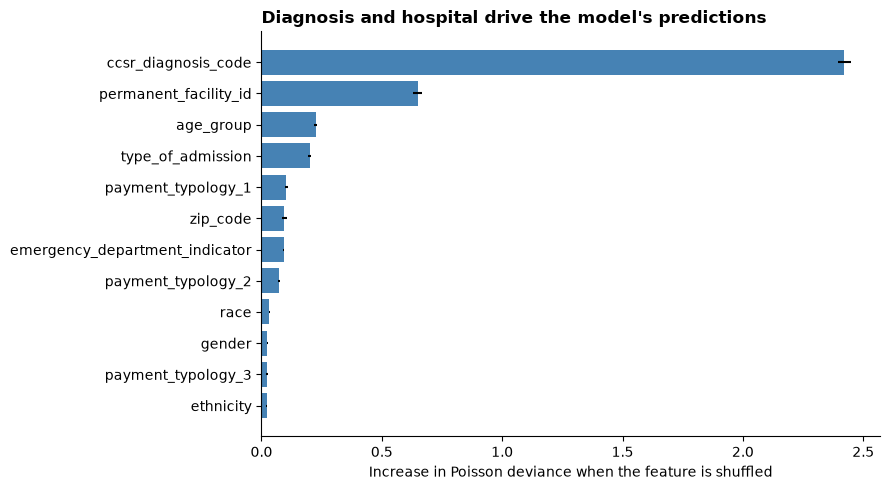

In [97]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

X_imp = X_test[ADMISSION].sample(50_000, random_state=RANDOM_STATE)
y_imp = y_test.loc[X_imp.index]

perm = permutation_importance(
    final_model, X_imp, y_imp,
    scoring="neg_mean_poisson_deviance",
    n_repeats=5,
    random_state=RANDOM_STATE,
)
importance = pd.DataFrame(
    {"increase_in_deviance": perm.importances_mean, "std": perm.importances_std},
    index=ADMISSION,
).sort_values("increase_in_deviance")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance.index, importance["increase_in_deviance"], xerr=importance["std"], color="steelblue")
ax.set_xlabel("Increase in Poisson deviance when the feature is shuffled")
ax.set_title("Diagnosis and hospital drive the model's predictions", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/permutation_importance.png", dpi=150, bbox_inches="tight")
importance.round(3).iloc[::-1]

In [100]:
# !pip install shap
import shap

preprocessor, booster = final_model[0], final_model[-1]

X_shap = X_imp.head(2000)
Z_shap = pd.DataFrame(
    preprocessor.transform(X_shap),
    columns=preprocessor.get_feature_names_out(),
    index=X_shap.index,
)
explanation = shap.TreeExplainer(booster)(Z_shap)

# One-hot columns belong together, so add them back up to the original feature
column_owner = [name.split("__")[1] for name in Z_shap.columns]
shap_by_feature = pd.DataFrame(
    {
        feature: explanation.values[:, [i for i, name in enumerate(column_owner) if name.startswith(feature)]].sum(axis=1)
        for feature in ADMISSION
    },
    index=X_shap.index,
)
shap_by_feature.abs().mean().sort_values(ascending=False).round(3)

c:\Users\nguye\anaconda3\envs\hospital-stay-forecast\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ccsr_diagnosis_code               0.347
permanent_facility_id             0.123
age_group                         0.078
payment_typology_1                0.045
type_of_admission                 0.038
payment_typology_2                0.028
race                              0.021
zip_code                          0.018
emergency_department_indicator    0.016
gender                            0.014
ethnicity                         0.011
payment_typology_3                0.007
dtype: float64

In [101]:
BASE_DAYS = np.exp(explanation.base_values[0])

def explain_patient(idx, top=5):
    predicted = final_model.predict(X_shap.loc[[idx]])[0]
    print(f"Actual: {y_test.loc[idx]} days | Predicted: {predicted:.1f} days | Average starting point: {BASE_DAYS:.1f} days")
    table = pd.DataFrame({
        "value": X_shap.loc[idx].astype(str),
        "multiplies_prediction_by": np.exp(shap_by_feature.loc[idx]),
    })
    order = shap_by_feature.loc[idx].abs().sort_values(ascending=False).index
    return table.loc[order].head(top).round(2)

shap_predictions = pd.Series(final_model.predict(X_shap), index=X_shap.index)
shap_errors = shap_predictions - y_test.loc[X_shap.index]

In [102]:
explain_patient(shap_errors.abs().idxmin())

Actual: 3 days | Predicted: 3.0 days | Average starting point: 5.2 days


,value,multiplies_prediction_by
ccsr_diagnosis_code,PRG022,0.49
permanent_facility_id,001464,1.20
payment_typology_1,Private Health Insurance,0.95
age_group,30-49,0.95
zip_code,109,1.04


In [103]:
explain_patient(shap_errors.idxmin())

Actual: 120 days | Predicted: 26.3 days | Average starting point: 5.2 days


,value,multiplies_prediction_by
ccsr_diagnosis_code,MBD001,3.35
permanent_facility_id,001301,1.29
payment_typology_2,Medicaid,1.07
ethnicity,Unknown,1.05
payment_typology_1,Medicare,1.05


## 10. Error analysis

MAE/RMSE/R2 by LOS band (1-3, 4-7, 8-14, 15-30, 31+ days), and by age group, race, payer, and admission type.

In [104]:
predictions = pd.Series(final_model.predict(X_test[ADMISSION]), index=X_test.index)
errors = pd.DataFrame({"actual": y_test, "predicted": predictions})
errors["absolute_error"] = (errors["predicted"] - errors["actual"]).abs()

def error_table(groups):
    table = errors.groupby(groups, observed=True).agg(
        rows=("actual", "size"),
        MAE=("absolute_error", "mean"),
        mean_actual=("actual", "mean"),
        mean_predicted=("predicted", "mean"),
    )
    table["bias"] = table["mean_predicted"] - table["mean_actual"]
    return table.round(2)

print(f"Median absolute error: {errors['absolute_error'].median():.2f} days")
print(f"Within 1 day: {(errors['absolute_error'] <= 1).mean():.1%}")
print(f"Within 2 days: {(errors['absolute_error'] <= 2).mean():.1%}")

Median absolute error: 2.31 days
Within 1 day: 24.5%
Within 2 days: 44.9%


In [105]:
los_bands = pd.cut(y_test, [0, 3, 7, 14, 30, 120], labels=["1-3", "4-7", "8-14", "15-30", "31+"])
by_band = error_table(los_bands)
by_band["baseline_MAE"] = (y_test - y_other.median()).abs().groupby(los_bands, observed=True).mean().round(2)
by_band

,rows,MAE,mean_actual,mean_predicted,bias,baseline_MAE
los,,,,,,
1-3,202788,2.75,1.95,4.63,2.68,1.05
4-7,109960,2.17,5.14,6.26,1.12,2.14
8-14,53560,3.85,10.30,8.15,-2.15,7.30
15-30,24781,10.52,20.13,10.14,-9.98,17.13
31+,7608,39.61,52.23,12.66,-39.57,49.23


In [106]:
subgroup_tables = {}
for column in ["age_group", "race", "ethnicity", "gender", "payment_typology_1", "type_of_admission"]:
    subgroup_tables[column] = error_table(X_test[column])

subgroups = pd.concat(subgroup_tables, names=["feature", "level"])
subgroups.to_csv("../results/subgroup_errors.csv")
subgroups

rows   MAE  mean_actual  \
feature            level                                                  
age_group          0-17                        20635  3.47         4.89   
                   18-29                       36371  2.83         4.81   
                   30-49                       84202  3.32         5.24   
                   50-69                      116260  4.56         6.61   
                   70 or Older                141229  4.10         6.53   
race               Black/African American      73990  4.75         7.00   
                   Multi-racial                 5731  3.83         5.92   
                   Other Race                 107761  3.88         5.84   
                   White                      211215  3.66         5.81   
ethnicity          Multi-ethnic                  477  3.65         5.69   
                   Not Span/Hispanic          284306  3.86         6.02   
                   Spanish/Hispanic            65422  3.61         5.51   
                   Unknown                     48492  4.69         6.90   
gender             F                          219091  3.39         5.49   
                   M                          179587  4.58         6.72   
                   U                              19  3.03         5.53   
payment_typology_1 Blue Cross/Blue Shield      33847  2.80         4.52   
                   Department of Corrections     303  4.89         6.87   
                   Federal/State/Local/VA       3779  3.57         5.54   
                   Managed Care, Unspecified    5363  3.29         5.03   
                   Medicaid                   106846  4.10         6.12   
                   Medicare                   185086  4.31         6.70   
                   Miscellaneous/Other          4261  4.51         6.21   
                   Not recorded                   42  3.03         4.79   
                   Private Health Insurance    53681  3.02         4.78   
                   Self-Pay                     5489  3.57         5.32   
type_of_admission  Elective                    70860  2.86         4.88   
                   Emergency                  291475  4.09         6.22   
                   Not Available                 719  5.62         8.95   
                   Trauma                       1994  5.11         7.08   
                   Urgent                      33649  4.57         6.82   

                                              mean_predicted  bias  
feature            level                                            
age_group          0-17                                 4.94  0.04  
                   18-29                                4.84  0.02  
                   30-49                                5.23 -0.01  
                   50-69                                6.62  0.01  
                   70 or Older                          6.54  0.01  
race               Black/African American               7.03  0.03  
                   Multi-racial                         5.95  0.03  
                   Other Race                           5.83 -0.01  
                   White                                5.82  0.01  
ethnicity          Multi-ethnic                         6.12  0.43  
                   Not Span/Hispanic                    6.03  0.02  
                   Spanish/Hispanic                     5.52  0.01  
                   Unknown                              6.86 -0.04  
gender             F                                    5.51  0.02  
                   M                                    6.71 -0.01  
                   U                                    6.13  0.61  
payment_typology_1 Blue Cross/Blue Shield               4.51 -0.01  
                   Department of Corrections            6.36 -0.51  
                   Federal/State/Local/VA               5.60  0.05  
                   Managed Care, Unspecified            5.07  0.05  
                   Medicaid                           

,predicted,actual
0,2.19,2.08
1,2.81,2.76
2,3.49,3.42
3,4.25,4.15
4,4.95,4.87
5,5.63,5.53
6,6.37,6.43
7,7.35,7.35
8,8.89,8.91
9,14.54,14.90


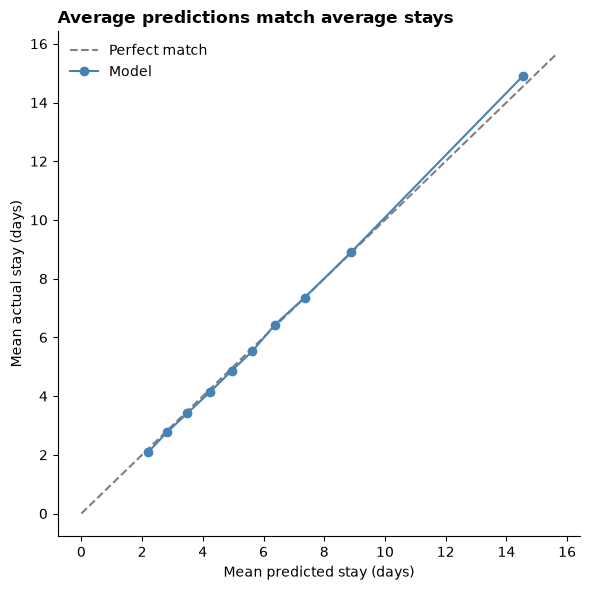

In [107]:
deciles = pd.qcut(predictions, 10, labels=False)
calibration = errors.groupby(deciles)[["predicted", "actual"]].mean()

fig, ax = plt.subplots(figsize=(6, 6))
limit = calibration.max().max() * 1.05
ax.plot([0, limit], [0, limit], color="gray", linestyle="--", label="Perfect match")
ax.plot(calibration["predicted"], calibration["actual"], "o-", color="steelblue", label="Model")
ax.set_xlabel("Mean predicted stay (days)")
ax.set_ylabel("Mean actual stay (days)")
ax.set_title("Average predictions match average stays", loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/calibration.png", dpi=150, bbox_inches="tight")
calibration.round(2)

In [108]:
error_table(X_test["ccsr_diagnosis_code"]).query("rows >= 2000").sort_values("MAE").tail(5)

,rows,MAE,mean_actual,mean_predicted,bias
ccsr_diagnosis_code,,,,,
GEN003,2649,6.05,7.92,8.15,0.23
INF002,32749,6.05,8.95,8.95,0.00
INJ008,2522,7.26,8.68,8.50,-0.18
MBD003,3159,7.28,12.90,12.26,-0.64
MBD001,7204,11.93,18.34,18.41,0.06


## 11. Conclusions and limitations

**Result.** A tuned Poisson gradient boosting model, using only admission-time features, reached
RMSE = 7.949 ± 0.043, MAE = 3.940 ± 0.007, and R² = 0.189 ± 0.002 across 5 random splits.
It beat predicting the mean (RMSE 8.769) and predicting the median (MAE 4.102) on the test set.

**Best use.** The model is well calibrated, and predicted total days are within 1% of actual,
so it suits planning total bed days. It isn't reliable for an individual patient: only 44.7% of
predictions are within 2 days, and it does worse than a constant 3-day guess on 1-3 day stays.

**Main drivers.** Principal diagnosis matters most, followed by hospital. Admission type and
age add smaller amounts. Permutation importance and SHAP agree on the top two.

**Limitations.**
- Principal diagnosis is finalized at discharge, so it only approximates what is known at admission.
  The real admission-time performance is probably somewhat lower.
- Long stays are heavily underpredicted (31+ days: 12.33 predicted vs 51.92 actual).
- Stays are capped at 120 days in the source, so the longest stays are censored.
- There are no patient IDs, so one patient's repeat admissions can appear in different splits.
- Hospitals unseen in training get an average encoding, so the model is built for known hospitals.
- There are no clinical measurements such as vitals or labs, which likely limits R².
- The data covers New York State in 2024 and may not generalize elsewhere or to later years.
- An untuned random forest scored about the same on validation; boosting was chosen for its lower fit time.